In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import random
import imageio.v3 as iio
import fastplotlib as fpl

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.
WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


Incompatible version of wgpu:
    Detected 0.15.3.post97+g8a0b267, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
movie = iio.imread("./demo_movie_mcorr.tiff")

In [4]:
movie.shape

(2000, 60, 80)

In [5]:
movie = movie[::2, ::1, ::1]

In [6]:
movie.shape

(1000, 60, 80)

In [7]:
movie -= movie.mean(axis=0)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
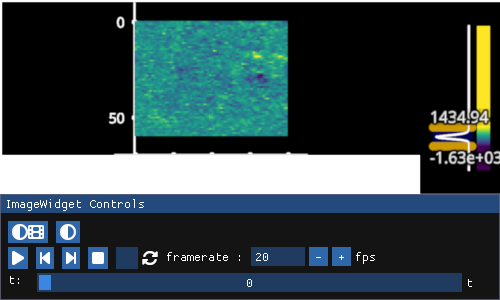

In [8]:
iw = fpl.ImageWidget(movie, cmap="viridis")
iw.show()

In [9]:
from skophys.preprocessing import Vectorizer, UnVectorizer

/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [10]:
X_init = Vectorizer().transform(movie)
unvec = UnVectorizer(movie.shape[1:])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
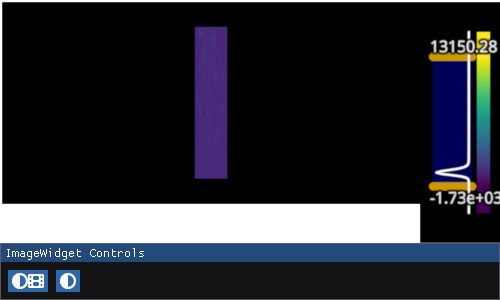

In [11]:
fpl.ImageWidget(X_init, cmap="viridis").show()

In [12]:
cov = X_init.T @ X_init

XTX = cov / np.linalg.norm(cov, ord="fro")

T = XTX.shape[0]

In [13]:
convergence = False
etamax = 0.1
eta = etamax

scounter = 1

In [45]:
k = 12

In [46]:
from tqdm.notebook import tqdm

In [47]:
Ys = list()

Y = (np.random.randn(k, T) / np.sqrt(T)).clip(0)

# Y /= Y.max()
# Y *= X.max()

for iteration in tqdm(range(7_000)):
    Ys.append(Y)
    Y_old = Y
    Y = Y + eta * Y @ (XTX - Y.T @ Y)
    Y = Y.clip(0)

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta

    if er < 1e-3:
        convergence = True
        break

  0%|          | 0/7000 [00:00<?, ?it/s]

In [48]:
er

np.float64(0.0037629908108696825)

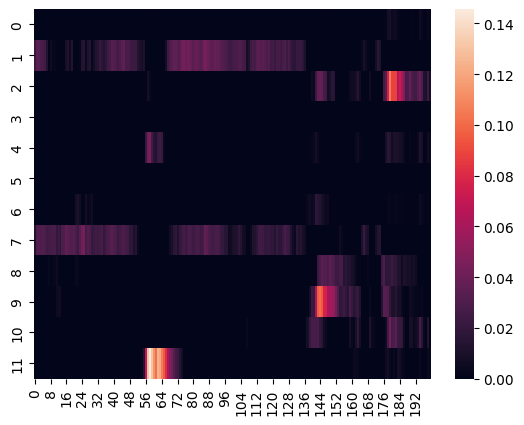

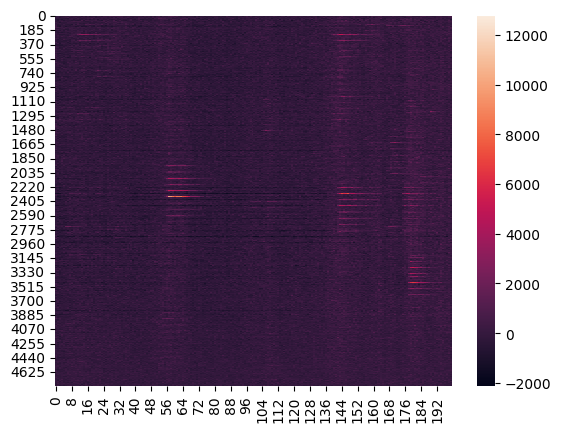

In [49]:
sns.heatmap(Y[:, :200])
plt.show()

sns.heatmap(X_init[:, :200])
plt.show()

In [50]:
W = Y @ X_init.T #/ sum_y_squared
M = Y @ Y.T #/ sum_y_squared

In [51]:
W.shape

(12, 4800)

In [52]:
Y.shape

(12, 1000)

<Axes: >

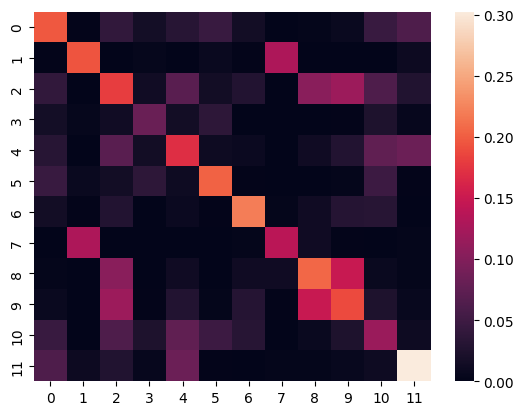

In [53]:
sns.heatmap(M)

In [54]:
np.linalg.eigvals(M)

array([0.50724511, 0.3591629 , 0.29861852, 0.2582153 , 0.21489714,
       0.1648976 , 0.14167855, 0.07021372, 0.06103321, 0.03138191,
       0.04593729, 0.04400858])

In [55]:
F = np.linalg.inv(M) @ W

In [56]:
F /= F.sum(axis=1)[:, None]

In [57]:
F.shape

(12, 4800)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
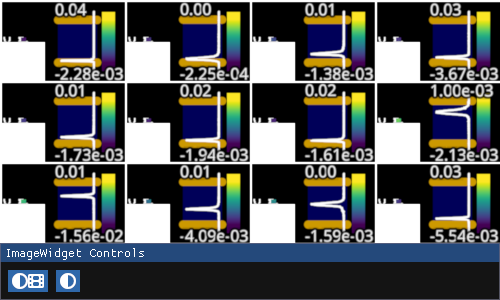

In [62]:
fpl.ImageWidget([a for a in unvec.transform(F.T)], names=[str(i) for i in range(F.shape[0])], cmap="viridis").show()

In [59]:
from ipywidgets import HBox

In [60]:
Y /= Y.max()
Y *= 10

In [65]:
iw_movie = fpl.ImageWidget(unvec.transform(X_init), cmap="viridis")
iw_movie.show()

fig = fpl.Figure()
lg = fig[0, 0].add_line(Y[11])
selector = lg.add_linear_selector()

@selector.add_event_handler("selection")
def index_changed(ev):
    ix = ev.get_selected_index()
    iw_movie.current_index = {"t": ix}

HBox([iw_movie.show(), fig.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

In [66]:
lg.data[:, 1] = Y[4]